# 3 · Correction from counts

*Roadmap:* [1 · Teleportation](01_teleportation.ipynb) → [2 · Channel noise](02_channel_noise.ipynb) → **3 · Correction from counts** → [4 · Automatic recalibration](04_automatic_recalibration.ipynb) → [5 · Incoherent noise and the ceiling](05_incoherent_noise_and_ceiling.ipynb) → [6 · Correlated noise](06_correlated_noise.ipynb) → [7 · Efficient learning and tracking](07_efficient_learning_and_tracking.ipynb) → [8 · Real hardware](08_real_hardware.ipynb)

**Question.** Notebook 2 showed that a rotation on the channel qubits, the inverse of the noise, restores the
message. But the noise is unknown. Can the correction be learned **from measurement counts alone**, without knowing
the noise or the message?

**The correction box.** Directly after the channel, one gate U(θ, φ, λ) acts on each channel qubit: six angles.
The channel is the coherent noise N1 of notebook 2.

In [1]:
import sys
try:
    import telecorr
except ImportError:                       # running from a source checkout without installation
    sys.path.insert(0, "../src"); import telecorr

import numpy as np
import matplotlib.pyplot as plt
from telecorr import protocol as P, channels as C, calibrate as K, probes as Pr
from telecorr.rotations import correction_rotations, oracle_angles
from telecorr.states import MESSAGES, message_state, random_message
from telecorr.twirl import f_avg_of
from telecorr.reference import simulation, number
from telecorr.plotting import use_style, CONDITION, INK_2
from telecorr.report import md_table, show, fmt
use_style()
T = C.leg_T()                                  # the channel: N1 (unknown to the calibrator)
MSG = [message_state(n) for n in MESSAGES]
RANDOM = [random_message(1000 + k) for k in range(30)]       # 30 Haar-random test messages (never used to calibrate)

## The model: a cost that can be measured

Three known **probe** states |00⟩, |++⟩, |+i+i⟩ are teleported through the channel and the correction box; Bob
applies the inverse of the probe's preparation and measures. P(00) is the probe's fidelity. By the twirl, the probe
along axis a survives on each leg with probability (1 + λ_a)/2, λ = diag(R T), and P(00) is the product over the two
legs (Theorem T3.5). The calibrator minimises the **probe cost**

$$C = 1 - \tfrac13 \left[P_{|00\rangle}(00) + P_{|{+}{+}\rangle}(00) + P_{|{+i}{+i}\rangle}(00)\right],$$

which needs only counts. It is pinned to the Haar-average fidelity of *all* messages (Theorem T3.6):

$$\tfrac56 (1 - F_\text{avg}) \;\le\; C \;\le\; \tfrac56 (1 - F_\text{avg}) + \tfrac{25}{48} (1 - F_\text{avg})^2 ,$$

so a small measured cost guarantees a high fidelity for every message, including ones never sent.

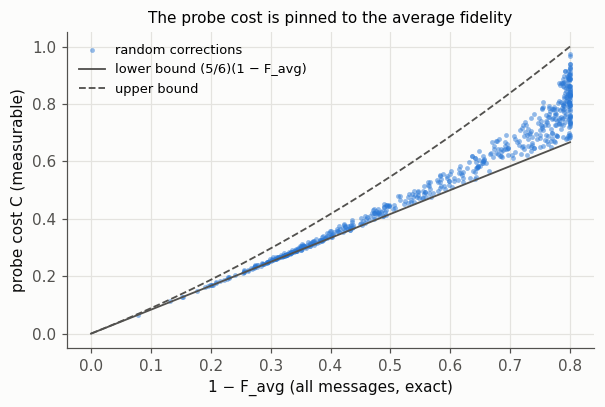

In [2]:
rng = np.random.default_rng(3)
xs = [rng.uniform(-np.pi, np.pi, 6) * rng.uniform(0, 1) for _ in range(600)]
g = np.array([1 - f_avg_of(correction_rotations(x), T) for x in xs]); c = np.array([Pr.cost(x, T) for x in xs])
gg = np.linspace(0, g.max(), 200)
fig, ax = plt.subplots(figsize=(5.6, 3.8))
ax.scatter(g, c, s=10, color=CONDITION["learned from counts"], alpha=0.5, lw=0, label="random corrections")
ax.plot(gg, 5 / 6 * gg, color=INK_2, lw=1.2, label="lower bound (5/6)(1 − F_avg)")
ax.plot(gg, 5 / 6 * gg + 25 / 48 * gg ** 2, color=INK_2, lw=1.2, ls="--", label="upper bound")
ax.set_xlabel("1 − F_avg (all messages, exact)"); ax.set_ylabel("probe cost C (measurable)")
ax.set_title("The probe cost is pinned to the average fidelity", fontsize=10)
ax.legend(fontsize=8.5, loc="upper left"); plt.tight_layout(); plt.show()

**The counts.** The calibrator below receives counts drawn from the exact distribution of the probe circuits
(multinomial, `calibrate.ProbeSampler`), which is what a simulator or a device produces. A check against the qiskit
circuits on the Aer simulator, at an arbitrary correction setting:

In [3]:
from scipy.stats import chi2
x_test = np.array([0.3, -1.0, 0.4, 1.1, 0.2, -0.7])
U = C.coherent_unitaries(); noise = [np.kron(U[3], U[2])]
rows = []
for k, name in enumerate(Pr.PROBE_AXIS):
    counts = P.bob_counts(P.circuit(name, "measured", unprepare=True, correction=x_test), 20000, seed=50 + k, pair_kraus=noise)
    p = Pr.probe_probs(x_test, T, (name,))[0]
    n = np.array([counts.get(key, 0) for key in ("00", "01", "10", "11")])
    x2 = float(((n - 20000 * p) ** 2 / (20000 * p)).sum())
    rows.append((name, fmt(p, 4), fmt(n / 20000, 4), x2, chi2.sf(x2, 3)))
show(md_table(rows, ["probe", "model: P(00, 01, 10, 11)", "Aer, 20 000 shots", "χ² (3 dof)", "p"], 3))

| probe | model: P(00, 01, 10, 11) | Aer, 20 000 shots | χ² (3 dof) | p |
|---|---|---|---|---|
| |00> | [0.1306, 0.0026, 0.8501, 0.0167] | [0.1301, 0.0032, 0.8505, 0.0163] | 3.434 | 0.329 |
| |++> | [0.2079, 0.0345, 0.6498, 0.1078] | [0.2112, 0.0369, 0.6447, 0.1073] | 5.098 | 0.165 |
| |+i+i> | [0.7638, 0.1152, 0.1051, 0.0159] | [0.7655, 0.1149, 0.1032, 0.0163] | 0.996 | 0.802 |

## The method: COBYLA in three phases

COBYLA (a derivative-free optimiser) minimises the measured cost from the zero setting (no correction). Each phase
uses more shots and smaller steps, so the shot-noise floor drops as the optimum is approached:
2 000 shots per probe (coarse), then 20 000, then 100 000.

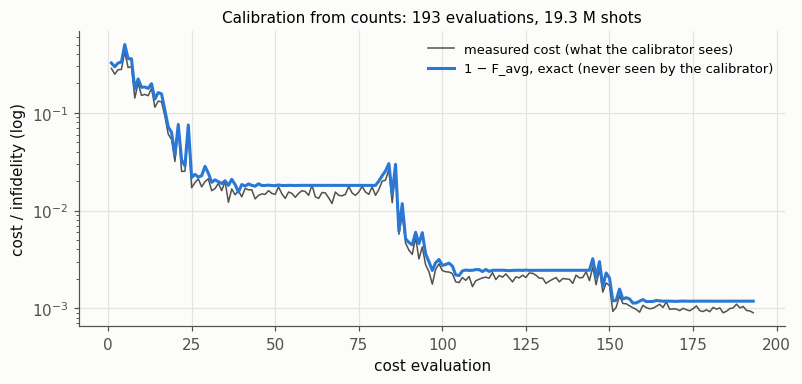

In [4]:
trace = []
sampler = K.ProbeSampler(T, np.random.default_rng(2024))
x_cal = K.cobyla(np.zeros(6), sampler, trace=trace)
ev = np.arange(1, len(trace) + 1)
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.semilogy(ev, [max(c, 1e-6) for _, c, _ in trace], color=INK_2, lw=1, label="measured cost (what the calibrator sees)")
ax.semilogy(ev, [1 - f_avg_of(correction_rotations(x), T) for _, _, x in trace], color=CONDITION["learned from counts"],
            label="1 − F_avg, exact (never seen by the calibrator)")
ax.set_xlabel("cost evaluation"); ax.set_ylabel("cost / infidelity (log)")
ax.set_title(f"Calibration from counts: {sampler.evals} evaluations, {sampler.shots / 1e6:.1f} M shots", fontsize=10)
ax.legend(fontsize=8.5, loc="upper right"); plt.tight_layout(); plt.show()

## Result

In [5]:
x_saved = np.array(simulation("stage3_calibration.json")["params"])
def row(label, x):
    sc = K.scores(x, T, MSG); fr = K.scores(x, T, RANDOM)["F"]
    res = K.residual_angles(x, T)
    return (label, *sc["F"], np.mean(fr), np.min(fr), *res)
rows = [row("no correction", None), row("calibrated from counts (this run)", x_cal),
        row("calibrated from counts (the study's saved run)", x_saved), row("exact inverse of N1", oracle_angles("N1"))]
show(md_table(rows, ["correction", "F product_HT", "F bell_30_70", "30 random messages: mean F", "min F",
                     "residual rotation q2 (rad)", "q3 (rad)"], 6))

| correction | F product_HT | F bell_30_70 | 30 random messages: mean F | min F | residual rotation q2 (rad) | q3 (rad) |
|---|---|---|---|---|---|---|
| no correction | 0.789767 | 0.607412 | 0.680857 | 0.608098 | 0.500000 | 1.300000 |
| calibrated from counts (this run) | 0.999213 | 0.998536 | 0.998810 | 0.998539 | 0.075762 | 0.013454 |
| calibrated from counts (the study's saved run) | 0.999906 | 0.999874 | 0.999891 | 0.999869 | 0.016449 | 0.016296 |
| exact inverse of N1 | 1.000000 | 1.000000 | 1.000000 | 1.000000 | 0.000000 | 0.000000 |

The fidelity reached is set by shot noise, so it varies from run to run. Thirty independent calibrations (same
channel, different random counts) show the spread, and where the study's saved run lies in it:

In [6]:
runs = []
for seed in range(30):
    x = K.cobyla(np.zeros(6), K.ProbeSampler(T, np.random.default_rng(seed)))
    runs.append(1 - f_avg_of(correction_rotations(x), T))
runs = np.array(runs); saved = 1 - f_avg_of(correction_rotations(x_saved), T)
show(md_table([("1 − F_avg", *np.percentile(runs, [10, 50, 90]), saved, (runs < saved).mean() * 100)],
              ["", "10 % of runs below", "median", "90 % of runs below", "the study's saved run", "percentile of the saved run"], 6))

|  | 10 % of runs below | median | 90 % of runs below | the study's saved run | percentile of the saved run |
|---|---|---|---|---|---|
| 1 − F_avg | 0.000066 | 0.000455 | 0.001674 | 0.000107 | 16.666667 |

## Why three probes: one probe is blind

A single probe along axis a cannot see a residual rotation *about* a: its cost is zero although the other
messages are damaged (Theorem T3.8). Calibrating with the |++⟩ probe alone:

In [7]:
x1 = K.cobyla(np.zeros(6), K.ProbeSampler(T, np.random.default_rng(11), probes=("|++>",)))
rows = [("|++> only", Pr.cost(x1, T, ("|++>",)), *K.scores(x1, T, MSG)["F"], np.mean(K.scores(x1, T, RANDOM)["F"]), *K.residual_angles(x1, T)),
        ("all three probes", Pr.cost(x_cal, T), *K.scores(x_cal, T, MSG)["F"], np.mean(K.scores(x_cal, T, RANDOM)["F"]), *K.residual_angles(x_cal, T))]
show(md_table(rows, ["probes used", "cost of these probes (exact)", "F product_HT", "F bell_30_70", "30 random messages: mean F",
                     "residual q2 (rad)", "residual q3 (rad)"], 4))

| probes used | cost of these probes (exact) | F product_HT | F bell_30_70 | 30 random messages: mean F | residual q2 (rad) | residual q3 (rad) |
|---|---|---|---|---|---|---|
| |++> only | 1.64e-06 | 0.9865 | 0.9731 | 0.9770 | 0.0766 | 0.3208 |
| all three probes | 0.0010 | 0.9992 | 0.9985 | 0.9988 | 0.0758 | 0.0135 |

## What it means

* **The correction can be learned from counts alone.** Three probe states and an optimiser that sees nothing but
  P(00) bring every message, including random ones never used, to F ≈ 0.999, limited only by shot noise.
* The probe cost is a faithful proxy: it is bounded on both sides by the average fidelity, and its minimum is the
  ideal correction. One probe is not enough; three are.

**Next (notebook 4):** this calibrator starts once, from zero, for a fixed channel. Real channels drift and jump,
and some noise settings trap a single start. Can the calibration watch the channel and repair itself?